In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv("marketing_campaign.csv", sep="\t")

print(df.head())
print("Dataset shape : ", df.shape)
print(df.info())

     ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957  Graduation         Single  58138.0        0         0   
1  2174        1954  Graduation         Single  46344.0        1         1   
2  4141        1965  Graduation       Together  71613.0        0         0   
3  6182        1984  Graduation       Together  26646.0        1         0   
4  5324        1981         PhD        Married  58293.0        1         0   

  Dt_Customer  Recency  MntWines  ...  NumWebVisitsMonth  AcceptedCmp3  \
0  04-09-2012       58       635  ...                  7             0   
1  08-03-2014       38        11  ...                  5             0   
2  21-08-2013       26       426  ...                  4             0   
3  10-02-2014       26        11  ...                  6             0   
4  19-01-2014       94       173  ...                  5             0   

   AcceptedCmp4  AcceptedCmp5  AcceptedCmp1  AcceptedCmp2  Complain  \
0             0

In [3]:
# Fill missing income values
df["Income"] = df["Income"].fillna(df["Income"].median())

# Convert registration date into datetime
df["Dt_Customer"] = pd.to_datetime(
    df["Dt_Customer"],
    dayfirst=True,
    errors="coerce"
)

# Calculate customer tenure
latest_date = df["Dt_Customer"].max()

df["Customer_Tenure_Days"] = (
    latest_date - df["Dt_Customer"]
).dt.days

# Remove unnecessary columns
df.drop(
    columns=[
        "ID",
        "Dt_Customer",
        "Z_CostContact",
        "Z_Revenue",
        "Response"
    ],
    inplace=True,
    errors="ignore"
)

print(df.head())

   Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  Recency  \
0        1957  Graduation         Single  58138.0        0         0       58   
1        1954  Graduation         Single  46344.0        1         1       38   
2        1965  Graduation       Together  71613.0        0         0       26   
3        1984  Graduation       Together  26646.0        1         0       26   
4        1981         PhD        Married  58293.0        1         0       94   

   MntWines  MntFruits  MntMeatProducts  ...  NumCatalogPurchases  \
0       635         88              546  ...                   10   
1        11          1                6  ...                    1   
2       426         49              127  ...                    2   
3        11          4               20  ...                    0   
4       173         43              118  ...                    3   

   NumStorePurchases  NumWebVisitsMonth  AcceptedCmp3  AcceptedCmp4  \
0                  4       

In [4]:
# Identify numerical and categorical columns
num_cols = df.select_dtypes(include=np.number).columns
cat_cols = df.select_dtypes(include="object").columns

# Fill missing numerical values
df[num_cols] = df[num_cols].fillna(
    df[num_cols].median()
)

# Fill missing categorical values
for col in cat_cols:
    df[col] = df[col].fillna(
        df[col].mode()[0]
    )

# Convert categorical columns into numerical columns
df_encoded = pd.get_dummies(
    df,
    columns=cat_cols,
    dtype=int
)

print(df_encoded.head())
print("Encoded shape:", df_encoded.shape)

   Year_Birth   Income  Kidhome  Teenhome  Recency  MntWines  MntFruits  \
0        1957  58138.0        0         0       58       635         88   
1        1954  46344.0        1         1       38        11          1   
2        1965  71613.0        0         0       26       426         49   
3        1984  26646.0        1         0       26        11          4   
4        1981  58293.0        1         0       94       173         43   

   MntMeatProducts  MntFishProducts  MntSweetProducts  ...  Education_Master  \
0              546              172                88  ...                 0   
1                6                2                 1  ...                 0   
2              127              111                21  ...                 0   
3               20               10                 3  ...                 0   
4              118               46                27  ...                 0   

   Education_PhD  Marital_Status_Absurd  Marital_Status_Alone  \
0  

C:\Users\acer\AppData\Local\Temp\ipykernel_11472\4209030823.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns


In [5]:
# Create total spending
spending_cols = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

df_encoded["Total_Spending"] = df_encoded[
    spending_cols
].sum(axis=1)

# Create total purchase count
purchase_cols = [
    "NumDealsPurchases",
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases"
]

df_encoded["Total_Purchases"] = df_encoded[
    purchase_cols
].sum(axis=1)

# Remove original columns used to calculate totals
df_encoded.drop(
    columns=spending_cols + purchase_cols,
    inplace=True,
    errors="ignore"
)

print(df_encoded.head())

   Year_Birth   Income  Kidhome  Teenhome  Recency  NumWebVisitsMonth  \
0        1957  58138.0        0         0       58                  7   
1        1954  46344.0        1         1       38                  5   
2        1965  71613.0        0         0       26                  4   
3        1984  26646.0        1         0       26                  6   
4        1981  58293.0        1         0       94                  5   

   AcceptedCmp3  AcceptedCmp4  AcceptedCmp5  AcceptedCmp1  ...  \
0             0             0             0             0  ...   
1             0             0             0             0  ...   
2             0             0             0             0  ...   
3             0             0             0             0  ...   
4             0             0             0             0  ...   

   Marital_Status_Absurd  Marital_Status_Alone  Marital_Status_Divorced  \
0                      0                     0                        0   
1             

In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(df_encoded)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (2240, 28)


In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("Number of selected features:", X_scaled.shape[1])

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=1000,
        random_state=42
    )

    print(f"K = {k}, Silhouette Score = {score:.4f}")

Number of selected features: 28
K = 2, Silhouette Score = 0.1124
K = 3, Silhouette Score = 0.0964
K = 4, Silhouette Score = 0.0929
K = 5, Silhouette Score = 0.1098
K = 6, Silhouette Score = 0.1171
K = 7, Silhouette Score = 0.0965
K = 8, Silhouette Score = 0.1086
K = 9, Silhouette Score = 0.1086
K = 10, Silhouette Score = 0.1170


In [8]:
# Apply K-Means with the best K
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

# Count customers in each cluster
print(df["KMeans_Cluster"].value_counts())

# Compare customer characteristics
df["Total_Spending"] = df[
    [
        "MntWines",
        "MntFruits",
        "MntMeatProducts",
        "MntFishProducts",
        "MntSweetProducts",
        "MntGoldProds"
    ]
].sum(axis=1)

summary = df.groupby("KMeans_Cluster")[
    ["Income", "Total_Spending"]
].mean().round(2)

print(summary)

KMeans_Cluster
1    1190
0    1050
Name: count, dtype: int64
                  Income  Total_Spending
KMeans_Cluster                          
0               70143.58         1128.65
1               36438.92          144.46


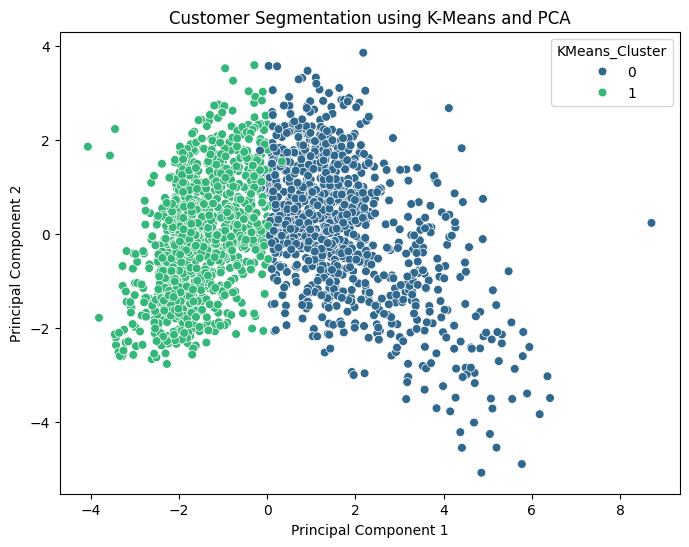

In [9]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Reduce data to two dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot the clusters
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df["KMeans_Cluster"],
    palette="viridis",
    s=40
)

plt.title("Customer Segmentation using K-Means and PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

In [10]:
# Count customers in each cluster
print("Number of customers in each cluster:")

print(df["KMeans_Cluster"].value_counts())

# Calculate total spending of each customer
spending_cols = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

df["Total_Spending"] = df[spending_cols].sum(axis=1)

# Compare the average characteristics of both clusters
summary = df.groupby("KMeans_Cluster")[
    ["Income", "Total_Spending"]
].mean().round(2)

print("\nCustomer Segmentation Summary:")
print(summary)

Number of customers in each cluster:
KMeans_Cluster
1    1190
0    1050
Name: count, dtype: int64

Customer Segmentation Summary:
                  Income  Total_Spending
KMeans_Cluster                          
0               70143.58         1128.65
1               36438.92          144.46


In [11]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# Apply DBSCAN using the correct variable X_scaled
dbscan = DBSCAN(eps=1.5, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

# Display cluster labels
print("DBSCAN Cluster Labels:")
print(set(dbscan_labels))

# Count customers in each cluster
print("\nNumber of customers in each cluster:")
print(pd.Series(dbscan_labels).value_counts().sort_index())

DBSCAN Cluster Labels:
{np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(51), np.int64(52), np.int64(53), np.int64(54), np.int64(-1)}

Number of customers in each cluster:
-1     1494
 0       16
 1        8
 2       57
 3       16
 4       81
 5       13
 6       53
 7       15
 8       18
 9       16
 10      52
 11      86
 12     

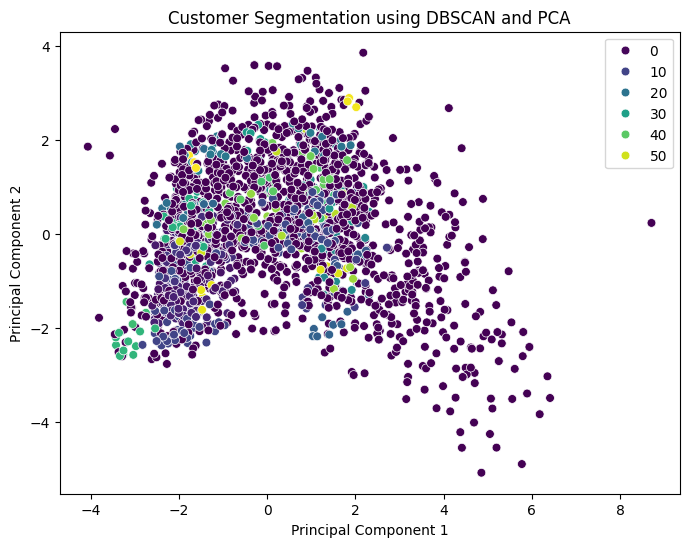

In [12]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# Reduce data to 2 dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Visualize DBSCAN clusters
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=dbscan_labels,
    palette="viridis",
    s=40
)

plt.title("Customer Segmentation using DBSCAN and PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

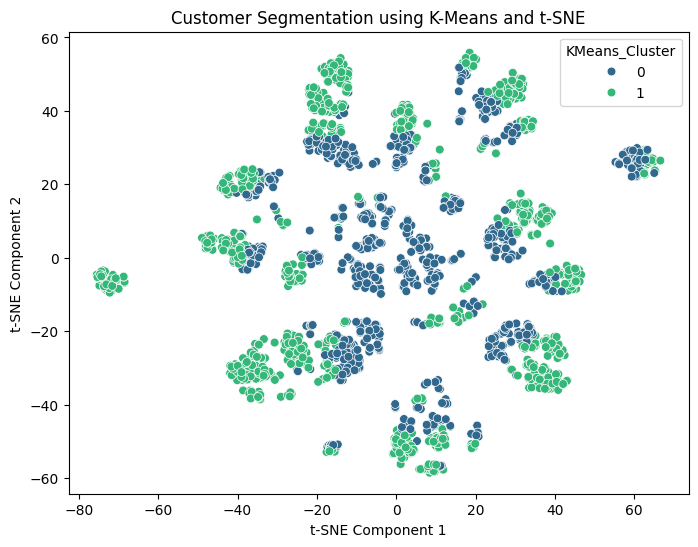

In [13]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns

# Reduce data to 2 dimensions using t-SNE
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    max_iter=1000
)

X_tsne = tsne.fit_transform(X_scaled)

# Visualize K-Means clusters
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=df["KMeans_Cluster"],
    palette="viridis",
    s=40
)

plt.title("Customer Segmentation using K-Means and t-SNE")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.show()

In [14]:
from sklearn.metrics import silhouette_score
import pandas as pd

# K-Means evaluation
kmeans_score = silhouette_score(
    X_scaled,
    df["KMeans_Cluster"],
    sample_size=1000,
    random_state=42
)

# DBSCAN evaluation
# Exclude noise points (-1) for silhouette calculation
mask = dbscan_labels != -1
dbscan_valid_labels = dbscan_labels[mask]
dbscan_valid_data = X_scaled[mask]

# Silhouette score requires at least 2 clusters
if len(set(dbscan_valid_labels)) >= 2:
    dbscan_score = silhouette_score(
        dbscan_valid_data,
        dbscan_valid_labels,
        sample_size=min(1000, len(dbscan_valid_labels)),
        random_state=42
    )
else:
    dbscan_score = None

# Display comparison
comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "DBSCAN"],
    "Silhouette Score": [kmeans_score, dbscan_score]
})

print(comparison)

  Algorithm  Silhouette Score
0   K-Means          0.112395
1    DBSCAN          0.305659


In [15]:
# Calculate total spending for each customer
spending_cols = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

df["Total_Spending"] = df[spending_cols].sum(axis=1)

# Generate cluster summary
cluster_summary = df.groupby("KMeans_Cluster").agg(
    Customer_Count=("KMeans_Cluster", "count"),
    Average_Income=("Income", "mean"),
    Average_Spending=("Total_Spending", "mean"),
    Average_Web_Purchases=("NumWebPurchases", "mean"),
    Average_Store_Purchases=("NumStorePurchases", "mean")
).round(2)

print("Customer Segmentation Analysis:")
print(cluster_summary)

Customer Segmentation Analysis:
                Customer_Count  Average_Income  Average_Spending  \
KMeans_Cluster                                                     
0                         1050        70143.58           1128.65   
1                         1190        36438.92            144.46   

                Average_Web_Purchases  Average_Store_Purchases  
KMeans_Cluster                                                  
0                                5.68                     8.33  
1                                2.68                     3.55  
